In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from lightgbm import LGBMRegressor

In [2]:
BASE_DIR = Path(
    "C:/Users/RSCH/Desktop/DWD/Final project/"
    "Retail-Intelligence-Platform"
)

DATASET_DIR = BASE_DIR / "datasets"

elasticity_file = DATASET_DIR / "elasticity_features.xlsx"
cleaned_file = DATASET_DIR / "amez_dataset_cleaned.xlsx"

In [3]:
elasticity_data = pd.read_excel(
    elasticity_file
)

print("Shape:", elasticity_data.shape)
print(elasticity_data.head())
print(elasticity_data.columns.tolist())

Shape: (11992, 8)
                              ProductID         InvoiceDate  Quantity  \
0  0128933d-9879-4346-aafc-a8045c36b087 2026-01-15 05:51:38         2   
1  0128933d-9879-4346-aafc-a8045c36b087 2026-01-16 06:21:19         4   
2  0128933d-9879-4346-aafc-a8045c36b087 2026-01-16 06:30:27         2   
3  0128933d-9879-4346-aafc-a8045c36b087 2026-01-17 06:55:34         2   
4  0128933d-9879-4346-aafc-a8045c36b087 2026-01-19 07:52:39         3   

   UnitPrice  Discount  EffectivePrice  PriceChange  DemandChange  
0    34267.0       500    34017.000000          NaN           NaN  
1    34748.0         0    34748.000000     0.021489           1.0  
2    32309.0      2000    31309.000000    -0.098970          -0.5  
3    34283.0         0    34283.000000     0.094989           0.0  
4    33196.0      4000    31862.666667    -0.070599           0.5  
['ProductID', 'InvoiceDate', 'Quantity', 'UnitPrice', 'Discount', 'EffectivePrice', 'PriceChange', 'DemandChange']


In [4]:
elasticity_data["InvoiceDate"] = pd.to_datetime(
    elasticity_data["InvoiceDate"],
    errors="coerce"
)

In [5]:
numeric_columns = [
    "Quantity",
    "UnitPrice",
    "Discount",
    "EffectivePrice",
    "PriceChange",
    "DemandChange"
]

for column in numeric_columns:
    elasticity_data[column] = pd.to_numeric(
        elasticity_data[column],
        errors="coerce"
    )

In [6]:
elasticity_data = elasticity_data.dropna(
    subset=[
        "ProductID",
        "InvoiceDate",
        "Quantity",
        "EffectivePrice"
    ]
).copy()

elasticity_data = elasticity_data[
    (elasticity_data["Quantity"] > 0) &
    (elasticity_data["EffectivePrice"] > 0)
].copy()

print("Rows available:", len(elasticity_data))

Rows available: 11989


In [7]:
price_demand = (
    elasticity_data.groupby(
        ["ProductID", "EffectivePrice"],
        as_index=False
    )
    .agg(
        TotalDemand=("Quantity", "sum"),
        SalesObservations=("InvoiceDate", "count")
    )
)

print(price_demand.head(10))

                              ProductID  EffectivePrice  TotalDemand  \
0  0128933d-9879-4346-aafc-a8045c36b087    29113.000000            1   
1  0128933d-9879-4346-aafc-a8045c36b087    29117.000000            1   
2  0128933d-9879-4346-aafc-a8045c36b087    30027.000000            2   
3  0128933d-9879-4346-aafc-a8045c36b087    30160.000000            2   
4  0128933d-9879-4346-aafc-a8045c36b087    30184.000000            2   
5  0128933d-9879-4346-aafc-a8045c36b087    30616.000000            1   
6  0128933d-9879-4346-aafc-a8045c36b087    31055.000000            2   
7  0128933d-9879-4346-aafc-a8045c36b087    31189.000000            2   
8  0128933d-9879-4346-aafc-a8045c36b087    31193.666667            3   
9  0128933d-9879-4346-aafc-a8045c36b087    31202.000000            1   

   SalesObservations  
0                  1  
1                  1  
2                  1  
3                  1  
4                  1  
5                  1  
6                  1  
7                  1  


In [8]:
product_id = price_demand["ProductID"].iloc[0]

product_data = price_demand[
    price_demand["ProductID"] == product_id
].sort_values("EffectivePrice")

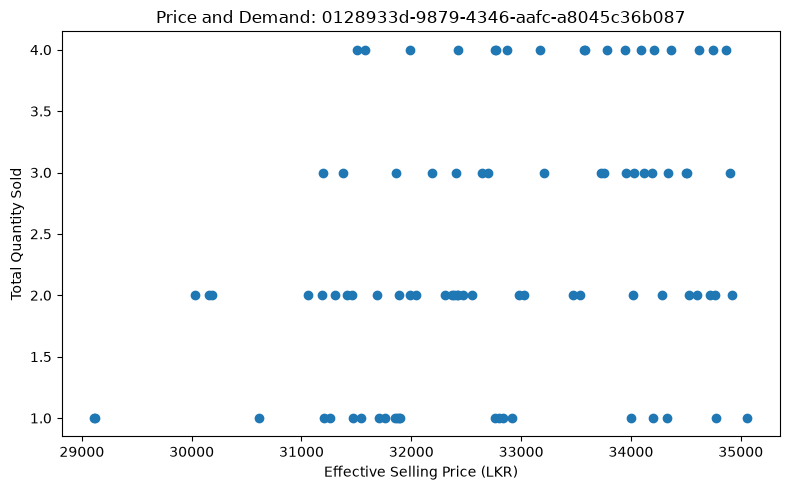

In [9]:
plt.figure(figsize=(8, 5))

plt.scatter(
    product_data["EffectivePrice"],
    product_data["TotalDemand"]
)

plt.xlabel("Effective Selling Price (LKR)")
plt.ylabel("Total Quantity Sold")
plt.title(f"Price and Demand: {product_id}")

plt.tight_layout()
plt.show()

In [10]:
def estimate_elasticity(product_data):

    product_data = product_data[
        (product_data["EffectivePrice"] > 0) &
        (product_data["TotalDemand"] > 0)
    ].copy()

    product_data = product_data.drop_duplicates(
        subset=["EffectivePrice"]
    )

    if len(product_data) < 3:
        return None

    log_price = np.log(
        product_data["EffectivePrice"]
    )

    log_demand = np.log(
        product_data["TotalDemand"]
    )

    slope = np.polyfit(
        log_price,
        log_demand,
        1
    )[0]

    return float(slope)

In [11]:
elasticity = estimate_elasticity(
    product_data
)

if elasticity is None:
    print(
        "Not enough distinct price observations."
    )
else:
    print(
        "Estimated elasticity:",
        round(elasticity, 3)
    )

Estimated elasticity: 3.747


In [12]:
elasticity_results = []

for product_id, group in price_demand.groupby(
    "ProductID"
):

    elasticity = estimate_elasticity(group)

    elasticity_results.append({
        "ProductID": product_id,
        "Elasticity": elasticity,
        "PriceObservations": (
            group["EffectivePrice"].nunique()
        )
    })

elasticity_df = pd.DataFrame(
    elasticity_results
)

print(elasticity_df.head())

                              ProductID  Elasticity  PriceObservations
0  0128933d-9879-4346-aafc-a8045c36b087    3.746624                 88
1  03df1a4a-b5a2-40ee-b621-f064b782d4a1    1.676465                 96
2  04df7b21-ab56-460d-96c8-25aed6e602a0    2.169678                 89
3  06a13e3b-0b08-40f7-bc7c-74fc8f197b7f    2.217897                 73
4  0a7982e2-2a56-4dea-b738-821ef43ca9ae    2.750905                 78


In [13]:
print(
    "Products with elasticity:",
    elasticity_df["Elasticity"].notna().sum()
)

print(
    "Products without enough observations:",
    elasticity_df["Elasticity"].isna().sum()
)

Products with elasticity: 121
Products without enough observations: 0


In [14]:
data = pd.read_excel(
    cleaned_file,
    sheet_name="Overall_Transactions"
)

print(data.shape)
print(data.columns.tolist())

(11992, 14)
['InvoiceID', 'InvoiceDate', 'CustomerID', 'ProductID', 'ProductName', 'Category', 'SubCategory', 'Quantity', 'UnitPrice', 'Discount', 'TotalAmount', 'StockQuantity', 'StoreID', 'StoreName']


In [15]:
data["Quantity"] = pd.to_numeric(
    data["Quantity"],
    errors="coerce"
)

data["StockQuantity"] = pd.to_numeric(
    data["StockQuantity"],
    errors="coerce"
)

In [16]:
inventory = (
    data.groupby(
        ["ProductID", "ProductName"],
        as_index=False
    )
    .agg(
        StockQuantity=("StockQuantity", "min"),
        TotalDemand=("Quantity", "sum")
    )
)

In [17]:
inventory["StockStatus"] = inventory[
    "StockQuantity"
].apply(
    lambda stock:
        "Low Stock"
        if stock <= 10
        else "Available"
)

In [18]:
print(inventory.head(20))

                               ProductID  \
0   0128933d-9879-4346-aafc-a8045c36b087   
1   03df1a4a-b5a2-40ee-b621-f064b782d4a1   
2   04df7b21-ab56-460d-96c8-25aed6e602a0   
3   06a13e3b-0b08-40f7-bc7c-74fc8f197b7f   
4   0a7982e2-2a56-4dea-b738-821ef43ca9ae   
5   0cc93738-8436-48b6-8d99-f7b664a19913   
6   10208917-4723-496b-965e-6ba280adfe4c   
7   11deee89-170f-41d4-9a10-3c9699f9e74f   
8   1598a930-ff4a-4af9-8456-cece32f2e2f9   
9   19adee70-c411-4b5e-8916-4ce0acca7cd6   
10  1bbe58d5-6bc3-47b0-a7f1-a355c56f9f21   
11  1dbf9c6a-e5a1-4f34-90df-bfacdfeeefb3   
12  1fe1e1ac-a58c-4353-8587-c042617f57f1   
13  222a621a-ad1d-45ba-b7dd-c60480d6510d   
14  29d2f94a-0e78-4297-bee3-6b53bcbed86c   
15  2c92a125-f75d-4b35-948c-f24478b5baa8   
16  2f9544c0-8675-4db7-9b66-a3558d3a5580   
17  343fc4ca-4e0c-441a-bb1c-6dc069a318aa   
18  35df6464-dcec-4649-975a-e7c6f96032e8   
19  3786ae6c-998f-4073-8efb-fac86c1d750c   

                               ProductName  StockQuantity  TotalDemand  \
0

In [19]:
print(
    inventory["StockStatus"].value_counts()
)

StockStatus
Available    121
Name: count, dtype: int64


In [20]:
pricing_features = elasticity_df.merge(
    inventory,
    on="ProductID",
    how="left"
)

In [21]:
print(pricing_features.head())

                              ProductID  Elasticity  PriceObservations  \
0  0128933d-9879-4346-aafc-a8045c36b087    3.746624                 88   
1  03df1a4a-b5a2-40ee-b621-f064b782d4a1    1.676465                 96   
2  04df7b21-ab56-460d-96c8-25aed6e602a0    2.169678                 89   
3  06a13e3b-0b08-40f7-bc7c-74fc8f197b7f    2.217897                 73   
4  0a7982e2-2a56-4dea-b738-821ef43ca9ae    2.750905                 78   

                             ProductName  StockQuantity  TotalDemand  \
0             Minimalist Wool Blend Coat             31          208   
1                 Modern Brass Desk Lamp             34          268   
2      Organic Turmeric Brightening Mask             36          221   
3      ClearSound USB-C Studio Earphones            108          192   
4  Signature CoreTime Premium Smartwatch             38          184   

  StockStatus  
0   Available  
1   Available  
2   Available  
3   Available  
4   Available  


In [22]:
model_data = elasticity_data.copy()

In [23]:
model_data["Revenue"] = (
    model_data["Quantity"] *
    model_data["EffectivePrice"]
)

In [24]:
model_data["DayOfWeek"] = (
    model_data["InvoiceDate"].dt.dayofweek
)

model_data["Month"] = (
    model_data["InvoiceDate"].dt.month
)

model_data["Day"] = (
    model_data["InvoiceDate"].dt.day
)

model_data["Year"] = (
    model_data["InvoiceDate"].dt.year
)

In [25]:
model_data = model_data.merge(
    inventory[
        [
            "ProductID",
            "StockQuantity",
            "StockStatus"
        ]
    ],
    on="ProductID",
    how="left"
)

In [26]:
model_data = model_data.merge(
    elasticity_df[
        [
            "ProductID",
            "Elasticity"
        ]
    ],
    on="ProductID",
    how="left"
)

In [27]:
features = [
    "EffectivePrice",
    "Discount",
    "DayOfWeek",
    "Month",
    "Day",
    "StockQuantity",
    "Elasticity"
]

In [28]:
target = "Quantity"

In [29]:
model_data = model_data.dropna(
    subset=features + [target]
).copy()

In [30]:
X = model_data[features]

y = model_data[target]

In [31]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [32]:
model = LGBMRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    num_leaves=31,
    random_state=42
)

In [33]:
print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

print("\nUnique values per feature:")
print(X.nunique())

print("\nTarget statistics:")
print(y.describe())

X shape: (11989, 7)
y shape: (11989,)

Features:
['EffectivePrice', 'Discount', 'DayOfWeek', 'Month', 'Day', 'StockQuantity', 'Elasticity']

Unique values per feature:
EffectivePrice    10377
Discount             32
DayOfWeek             7
Month                 8
Day                  31
StockQuantity        36
Elasticity          121
dtype: int64

Target statistics:
count    11989.000000
mean         2.363500
std          1.242994
min          1.000000
25%          1.000000
50%          2.000000
75%          3.000000
max          5.000000
Name: Quantity, dtype: float64


In [34]:
print("\nMissing values:")
print(X.isnull().sum())

print("\nConstant features:")
for column in X.columns:
    if X[column].nunique() <= 1:
        print(column)


Missing values:
EffectivePrice    0
Discount          0
DayOfWeek         0
Month             0
Day               0
StockQuantity     0
Elasticity        0
dtype: int64

Constant features:


In [35]:
model.fit(
    X_train,
    y_train
)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.003709 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 490
[LightGBM] [Info] Number of data points in the train set: 9591, number of used features: 7
[LightGBM] [Info] Start training from score 2.356584


[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No f

,max_depth,6
,learning_rate,0.05
,n_estimators,300
,random_state,42
,boosting_type,'gbdt'
,num_leaves,31
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001


In [36]:
y_pred = model.predict(X_test)

In [37]:
print(X.columns.tolist())
print(X.nunique())
print(y.describe())

['EffectivePrice', 'Discount', 'DayOfWeek', 'Month', 'Day', 'StockQuantity', 'Elasticity']
EffectivePrice    10377
Discount             32
DayOfWeek             7
Month                 8
Day                  31
StockQuantity        36
Elasticity          121
dtype: int64
count    11989.000000
mean         2.363500
std          1.242994
min          1.000000
25%          1.000000
50%          2.000000
75%          3.000000
max          5.000000
Name: Quantity, dtype: float64


In [38]:
mae = mean_absolute_error(
    y_test,
    y_pred
)

rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred
    )
)

r2 = r2_score(
    y_test,
    y_pred
)

In [39]:
print("MAE:", round(mae, 3))
print("RMSE:", round(rmse, 3))
print("R²:", round(r2, 3))

MAE: 0.847
RMSE: 1.064
R²: 0.278


In [40]:
print(features)
print(X.columns.tolist())

['EffectivePrice', 'Discount', 'DayOfWeek', 'Month', 'Day', 'StockQuantity', 'Elasticity']
['EffectivePrice', 'Discount', 'DayOfWeek', 'Month', 'Day', 'StockQuantity', 'Elasticity']


In [41]:
X = model_data[features]
y = model_data["Quantity"]

In [42]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [43]:
model = LGBMRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    num_leaves=31,
    random_state=42,
    verbosity=-1
)

model.fit(
    X_train,
    y_train
)

,max_depth,6
,learning_rate,0.05
,n_estimators,300
,random_state,42
,verbosity,-1
,boosting_type,'gbdt'
,num_leaves,31
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0


In [44]:
y_pred = model.predict(X_test)

mae = mean_absolute_error(
    y_test,
    y_pred
)

rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred
    )
)

r2 = r2_score(
    y_test,
    y_pred
)

print("MAE:", round(mae, 3))
print("RMSE:", round(rmse, 3))
print("R²:", round(r2, 3))

MAE: 0.847
RMSE: 1.064
R²: 0.278


In [45]:
model_folder = (
    BASE_DIR /
    "backend" /
    "ml" /
    "pricing" /
    "models"
)

model_folder.mkdir(
    parents=True,
    exist_ok=True
)


In [46]:
model_path = (
    model_folder /
    "lightgbm_demand_model.pkl"
)

joblib.dump(
    model,
    model_path
)

print(
    "Model saved to:",
    model_path
)



Model saved to: C:\Users\RSCH\Desktop\DWD\Final project\Retail-Intelligence-Platform\backend\ml\pricing\models\lightgbm_demand_model.pkl


In [47]:

features_path = (
    model_folder /
    "pricing_features.pkl"
)

joblib.dump(
    features,
    features_path
)


['C:\\Users\\RSCH\\Desktop\\DWD\\Final project\\Retail-Intelligence-Platform\\backend\\ml\\pricing\\models\\pricing_features.pkl']

In [48]:
model.fit(X_train, y_train)

,max_depth,6
,learning_rate,0.05
,n_estimators,300
,random_state,42
,verbosity,-1
,boosting_type,'gbdt'
,num_leaves,31
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0


In [49]:
test_prediction = model.predict(
    X_test.head(10)
)

print("Test predictions:")
print(test_prediction)

print()
print("Actual values:")
print(y_test.head(10).values)

Test predictions:
[2.2243213  1.7173731  2.60100116 2.46390165 1.7915443  2.44953772
 2.1075192  2.90950309 2.12835631 2.19236525]

Actual values:
[3 1 3 1 1 3 1 3 1 2]


In [50]:
print("Prediction minimum:", test_prediction.min())
print("Prediction maximum:", test_prediction.max())
print("Prediction mean:", test_prediction.mean())

Prediction minimum: 1.717373104045412
Prediction maximum: 2.909503085867517
Prediction mean: 2.258542307433727


In [51]:
print("Model type:")
print(type(model))

print()

print("Model features:")
print(features)

print()

print("Model prediction for test input:")

test_input = pd.DataFrame([
    {
        "EffectivePrice": 1400,
        "Discount": 100,
        "DayOfWeek": 2,
        "Month": 10,
        "Day": 6,
        "StockQuantity": 50,
        "Elasticity": -1.2
    }
])

test_input = test_input[features]

print(test_input)

prediction = model.predict(test_input)

print()
print("Prediction:")
print(prediction)

Model type:
<class 'lightgbm.sklearn.LGBMRegressor'>

Model features:
['EffectivePrice', 'Discount', 'DayOfWeek', 'Month', 'Day', 'StockQuantity', 'Elasticity']

Model prediction for test input:
   EffectivePrice  Discount  DayOfWeek  Month  Day  StockQuantity  Elasticity
0            1400       100          2     10    6             50        -1.2

Prediction:
[-0.19287131]


In [52]:
import joblib

saved_model = joblib.load(
    "../backend/ml/pricing/models/lightgbm_demand_model.pkl"
)

saved_features = joblib.load(
    "../backend/ml/pricing/models/pricing_features.pkl"
)

print("Saved model:")
print(type(saved_model))

print()

print("Saved features:")
print(saved_features)

Saved model:
<class 'lightgbm.sklearn.LGBMRegressor'>

Saved features:
['EffectivePrice', 'Discount', 'DayOfWeek', 'Month', 'Day', 'StockQuantity', 'Elasticity']


In [53]:
test_input = pd.DataFrame([
    {
        "EffectivePrice": 1400,
        "Discount": 100,
        "DayOfWeek": 2,
        "Month": 10,
        "Day": 6,
        "StockQuantity": 50,
        "Elasticity": -1.2
    }
])

test_input = test_input[saved_features]

saved_prediction = saved_model.predict(
    test_input
)

print("Saved model prediction:")
print(saved_prediction)

Saved model prediction:
[-0.19287131]


In [ ]:
print("Training feature ranges:")
print(X.describe().T)

In [54]:
print("Training feature ranges:")
print(X.describe().T)
print("Training target range:")
print(y.describe())
print("Real test input example:")
print(X_test.head(10))
real_input = X_test.iloc[[0]]

print("Real input:")
print(real_input)

real_prediction = model.predict(real_input)

print()
print("Prediction:")
print(real_prediction)

print()
print("Actual demand:")
print(y_test.iloc[0])

Training feature ranges:
                  count          mean           std       min          25%  \
EffectivePrice  11989.0  25116.556527  31501.053229  25.00000  7967.000000   
Discount        11989.0   1592.951372   1675.727175   0.00000   500.000000   
DayOfWeek       11989.0      3.022521      1.978781   0.00000     1.000000   
Month           11989.0      4.269831      2.067878   1.00000     3.000000   
Day             11989.0     15.522145      8.779875   1.00000     8.000000   
StockQuantity   11989.0     40.241471     17.232289  23.00000    31.000000   
Elasticity      11989.0      2.486414      1.132269  -0.45324     1.700429   

                         50%           75%            max  
EffectivePrice  14895.000000  31015.000000  200567.000000  
Discount         1500.000000   2500.000000   45000.000000  
DayOfWeek           3.000000      5.000000       6.000000  
Month               4.000000      6.000000       8.000000  
Day                15.000000     23.000000      31